# Understanding the MovieLens training data

This notebook is our first step toward explaining **where the rating model works, where it fails, and why**. We inspect training ratings and corrected movie metadata before running models.

Run the cells from top to bottom. Each plot includes a question and guidance for interpretation. No models are trained and no project configuration is changed. Test ratings are used only for structural checks, never for plots or model selection.

**Data contract:** row `u` is a user, column `j` is a movie, and `NaN` means an unknown rating. Metadata row `j` and `movie_ids[j]` describe ratings column `j`. A missing rating is neither a zero nor evidence of dislike.

In [3]:
from pathlib import Path
import re
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({'figure.figsize': (10, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})
# Search only the project and its parent, so VS Code can start in either folder.
PROJECT_NAME = 'masteriasd-datalab-project-a1-group-38'
cwd = Path.cwd().resolve()
project_candidates = [cwd, cwd / PROJECT_NAME, cwd.parent / PROJECT_NAME]
PROJECT = next((p for p in project_candidates if (p / 'models.py').is_file()), None)
if PROJECT is None:
    raise FileNotFoundError('Start this notebook from the project folder or its parent.')
roots = list(dict.fromkeys([PROJECT, PROJECT.parent]))
def locate(name):
    matches = [p / name for p in roots if (p / name).is_file()]
    if not matches:
        raise FileNotFoundError(f'{name} not found in {roots}')
    if len(matches) > 1 and matches[0].read_bytes() != matches[1].read_bytes():
        raise ValueError(f'Conflicting copies of {name}: {matches}. Resolve before analysis.')
    return matches[0]

paths = {name: locate(name) for name in
         ['ratings_train.npy', 'ratings_test.npy', 'namesngenre.npy', 'movie_ids.npy']}
display(pd.Series({k: str(v) for k, v in paths.items()}, name='Loaded from').to_frame())
train = np.load(paths['ratings_train.npy'], allow_pickle=False)
test = np.load(paths['ratings_test.npy'], allow_pickle=False)
metadata = np.load(paths['namesngenre.npy'], allow_pickle=False)
movie_ids = np.load(paths['movie_ids.npy'], allow_pickle=False)
observed = np.isfinite(train)

,Loaded from
ratings_train.npy,C:\Users\User\Desktop\Mines_Paris_cours\IASD_m...
ratings_test.npy,C:\Users\User\Desktop\Mines_Paris_cours\IASD_m...
namesngenre.npy,C:\Users\User\Desktop\Mines_Paris_cours\IASD_m...
movie_ids.npy,C:\Users\User\Desktop\Mines_Paris_cours\IASD_m...


## 1. Check the data before interpreting it

The supplied correction notice, `README-A1.txt`, identifies the renamed `namesngenre.npy` as the corrected metadata. Equal array lengths alone cannot prove alignment; we rely on that supplied mapping. Original MovieLens IDs are preferable to titles for joins because titles are not unique.

These checks verify shapes, valid rating values, unique movie IDs, and disjoint train/test cells. They do not make the test set historically untouched: earlier project development already used it.

In [4]:
assert train.ndim == 2 and train.shape == test.shape
assert metadata.shape == (train.shape[1], 2)
assert movie_ids.shape == (train.shape[1],)
assert len(np.unique(movie_ids)) == len(movie_ids)
assert not np.any(observed & np.isfinite(test)), 'Train/test overlap'
allowed = np.arange(0.5, 5.01, 0.5)
for name, x in [('train', train), ('test', test)]:
    assert not np.isinf(x).any(), f'Infinite values in {name}'
    assert np.isin(x[np.isfinite(x)], allowed).all(), f'Invalid ratings in {name}'
summary = pd.DataFrame([
    {'split': name, 'users': x.shape[0], 'movies': x.shape[1],
     'known ratings': int(np.isfinite(x).sum()),
     'observed cells (%)': 100 * np.isfinite(x).mean()}
    for name, x in [('train', train), ('test', test)]
]).set_index('split')
display(summary.round(3))
# Drop test labels now: the remaining analysis uses training data only.
del test
user_counts = observed.sum(axis=1)
movie_counts = observed.sum(axis=0)
values = train[observed]
movies = pd.DataFrame({'column': np.arange(train.shape[1]), 'movieId': movie_ids,
                       'title': metadata[:, 0], 'genres': metadata[:, 1],
                       'train_ratings': movie_counts})
movies['year'] = pd.to_numeric(movies['title'].str.extract(r'\((\d{4})\)\s*$')[0], errors='coerce')
display(movies.head())

,users,movies,known ratings,observed cells (%)
split,,,,
train,610,4980,31598,1.04
test,610,4980,31598,1.04


,column,movieId,title,genres,train_ratings,year
0,0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,72,1995.0
1,1,2,Jumanji (1995),Adventure|Children|Fantasy,37,1995.0
2,2,3,Grumpier Old Men (1995),Comedy|Romance,17,1995.0
3,3,4,Waiting to Exhale (1995),Comedy|Drama|Romance,2,1995.0
4,4,5,Father of the Bride Part II (1995),Comedy,17,1995.0


## 2. What do the training examples look like?

Each observed cell is one supervised example: **(user, movie) ? star rating**. There are no user demographics in these arrays. Movie IDs identify movies but are not numerical measurements of their content.

The example below uses zero-based matrix indices. We do not assume that a matrix row index is an original MovieLens user ID.

**Reading the example table:** every `user row` is 0 because we selected only the first user (`example_user = 0`). Each table row is a different movie rated by that same user. `column` is the movie?s position in our matrix (starting at 0); `movieId` is its identifier in the original MovieLens database. They are different numbering systems: this project keeps a subset of movies, so original IDs can have gaps. The leftmost unlabeled table index is a pandas row label.

**Zero-based indexing:** the first row/column is 0, the second is 1. Thus `train[0, 44]` means the first user and the 45th movie column. A row position tells us where the user is stored; without an explicit original-user-ID mapping, it does not establish their MovieLens user ID. We do have an explicit movie mapping in `movie_ids.npy`.


In [5]:
example_user = 0
cols = np.flatnonzero(observed[example_user])[:10]
examples = movies.iloc[cols][['column', 'movieId', 'title', 'genres']].copy()
examples.insert(0, 'user row', example_user)
examples['rating'] = train[example_user, cols]
display(examples)

,user row,column,movieId,title,genres,rating
0,0,0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,4.0
44,0,44,50,"Usual Suspects, The (1995)",Crime|Mystery|Thriller,5.0
58,0,58,70,From Dusk Till Dawn (1996),Action|Comedy|Horror|Thriller,3.0
86,0,86,110,Braveheart (1995),Action|Drama|War,4.0
104,0,104,151,Rob Roy (1995),Action|Drama|Romance|War,5.0
153,0,153,216,Billy Madison (1995),Comedy,5.0
168,0,168,235,Ed Wood (1994),Comedy|Drama,4.0
187,0,187,260,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi,5.0
296,0,296,423,Blown Away (1994),Action|Thriller,3.0
394,0,394,553,Tombstone (1993),Action|Drama|Western,5.0


## 3. Which ratings are common?

**Question:** Is the target distribution balanced? A model optimizing RMSE may predict common middle-to-high scores more often than extreme scores.

This is the distribution of **observed opinions**, not of all movies a user might watch. People choose what to watch and rate, so missingness need not be random. The plot alone does not explain why any particular user rated a movie.

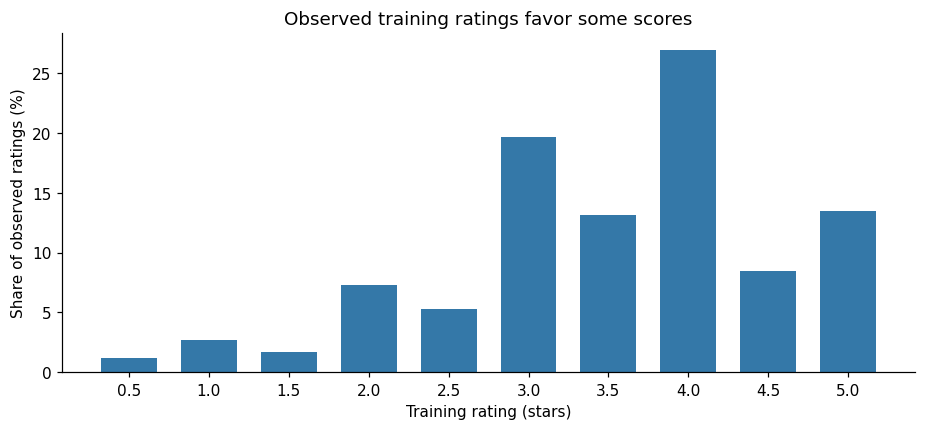

Training mean: 3.525 stars; median: 3.5 stars


In [6]:
rating_counts = pd.Series(values).value_counts().reindex(allowed, fill_value=0)
fig, ax = plt.subplots()
ax.bar(rating_counts.index, 100 * rating_counts / rating_counts.sum(), width=.35, color='#3478a8')
ax.set(xlabel='Training rating (stars)', ylabel='Share of observed ratings (%)',
       title='Observed training ratings favor some scores', xticks=allowed)
plt.show()
print(f'Training mean: {values.mean():.3f} stars; median: {np.median(values):.1f} stars')

## 4. How uneven is the evidence per user and movie?

**Question:** Does the typical entity have enough observations to learn its preferences or characteristics?

These counts are called **support**. The logarithmic count axis makes the long tail visible. A movie with three ratings supplies much less evidence than one with a hundred, even though both have their own latent vector in matrix factorization. This motivates regularization and metadata-informed priors.

**Reading the summary table:** `users` describes the number of training ratings per user; `movies` describes the number of training ratings per movie. The user mean (about 51.8) is 31,598 / 610; it is an average, not a fractional movie rated by one person. The user maximum (815) means one user has 815 observed movie ratings in training. The movie mean (about 6.35) is 31,598 / 4,980; the movie maximum (109) means one movie has ratings from 109 users in training. `count` is the number of users or movies; `std` measures the spread of their counts; `50%` is the median. These counts exclude test ratings.

**Reading the plots:** on the left, x is the number of training movies rated by a user and y is the number of users in that interval. On the right, x is the number of training users who rated a movie and y is the number of movies in that interval. Bar heights count entities, not star ratings. The dashed line marks the median. The x-axis is logarithmic: equal distances represent multiplicative changes (for example, 1 to 10 and 10 to 100), not equal additions. The bins also vary in width, so interpret each bar as a count in its labeled x interval.


,users,movies
count,610.0,4980.0
mean,51.8,6.3
std,79.2,9.6
min,2.0,1.0
10%,7.0,1.0
25%,11.2,1.0
50%,24.0,3.0
75%,57.0,7.0
90%,124.1,15.0
99%,377.7,48.0


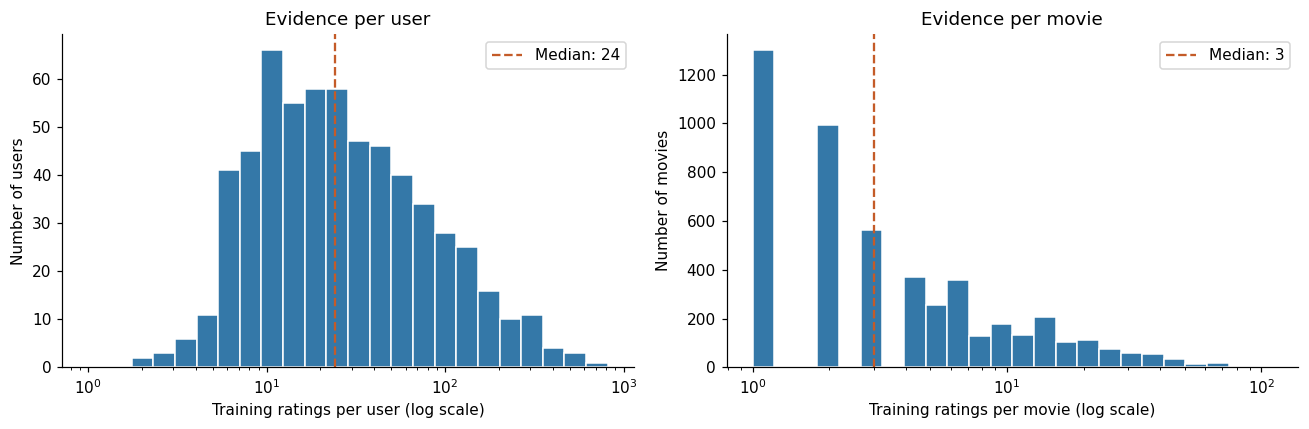

Users with no training ratings: 0
Movies with no training ratings: 0


In [7]:
support = pd.DataFrame({'users': pd.Series(user_counts).describe(percentiles=[.1, .25, .5, .75, .9, .99]),
                        'movies': pd.Series(movie_counts).describe(percentiles=[.1, .25, .5, .75, .9, .99])})
display(support.round(1))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, counts, label in zip(axes, [user_counts, movie_counts], ['user', 'movie']):
    bins = np.geomspace(1, max(2, counts.max()) + 1, 25)
    ax.hist(counts[counts > 0], bins=bins, color='#3478a8', edgecolor='white')
    ax.set_xscale('log')
    ax.axvline(np.median(counts), color='#c45b28', linestyle='--', label=f'Median: {np.median(counts):g}')
    ax.set(xlabel=f'Training ratings per {label} (log scale)', ylabel=f'Number of {label}s', title=f'Evidence per {label}')
    ax.legend()
plt.tight_layout()
plt.show()
print('Users with no training ratings:', int((user_counts == 0).sum()))
print('Movies with no training ratings:', int((movie_counts == 0).sum()))

## 5. How much of the training signal comes from popular movies?

The catalogue gives each movie equal weight; RMSE gives each held-out **rating** equal weight. Those are different perspectives. The table compares the catalogue share with the observed training-rating share for each support group.

A large group of rarely rated movies can contribute relatively few ratings. Later we should report error by support as well as overall RMSE. The matrix preview is a fixed random subset, not a display of rating values: white means missing and blue means observed.

,movies,ratings,catalogue share (%),training-rating share (%)
support group,,,,
0,0,0,0.00,0.00
1?4,3228,6458,64.82,20.44
5?19,1404,13183,28.19,41.72
20+,348,11957,6.99,37.84


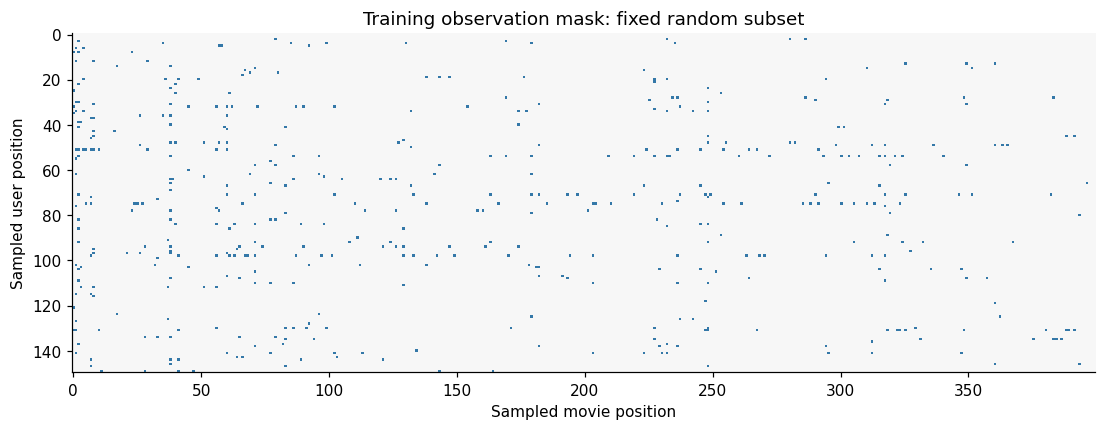

In [8]:
movies['support group'] = pd.cut(movie_counts, [-1, 0, 4, 19, np.inf], labels=['0', '1?4', '5?19', '20+'])
by_support = movies.groupby('support group', observed=False).agg(movies=('movieId', 'size'), ratings=('train_ratings', 'sum'))
by_support['catalogue share (%)'] = 100 * by_support['movies'] / len(movies)
by_support['training-rating share (%)'] = 100 * by_support['ratings'] / observed.sum()
display(by_support.round(2))
rng = np.random.default_rng(2026)
u = np.sort(rng.choice(train.shape[0], min(150, train.shape[0]), replace=False))
i = np.sort(rng.choice(train.shape[1], min(400, train.shape[1]), replace=False))
from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(12, 4))
ax.imshow(observed[np.ix_(u, i)], aspect='auto', interpolation='nearest', cmap=ListedColormap(['#f7f7f7', '#3478a8']), vmin=0, vmax=1)
ax.set(title='Training observation mask: fixed random subset', xlabel='Sampled movie position', ylabel='Sampled user position')
plt.show()

## 6. Genres: catalogue coverage versus observed ratings

**Question:** Are genres represented similarly among available movies and observed ratings?

A movie may carry multiple genres, so the percentages do **not** sum to 100%. A rating of a comedy-drama contributes to both genre totals. The second panel counts ratings, not unique users, viewing events, or population-wide popularity.

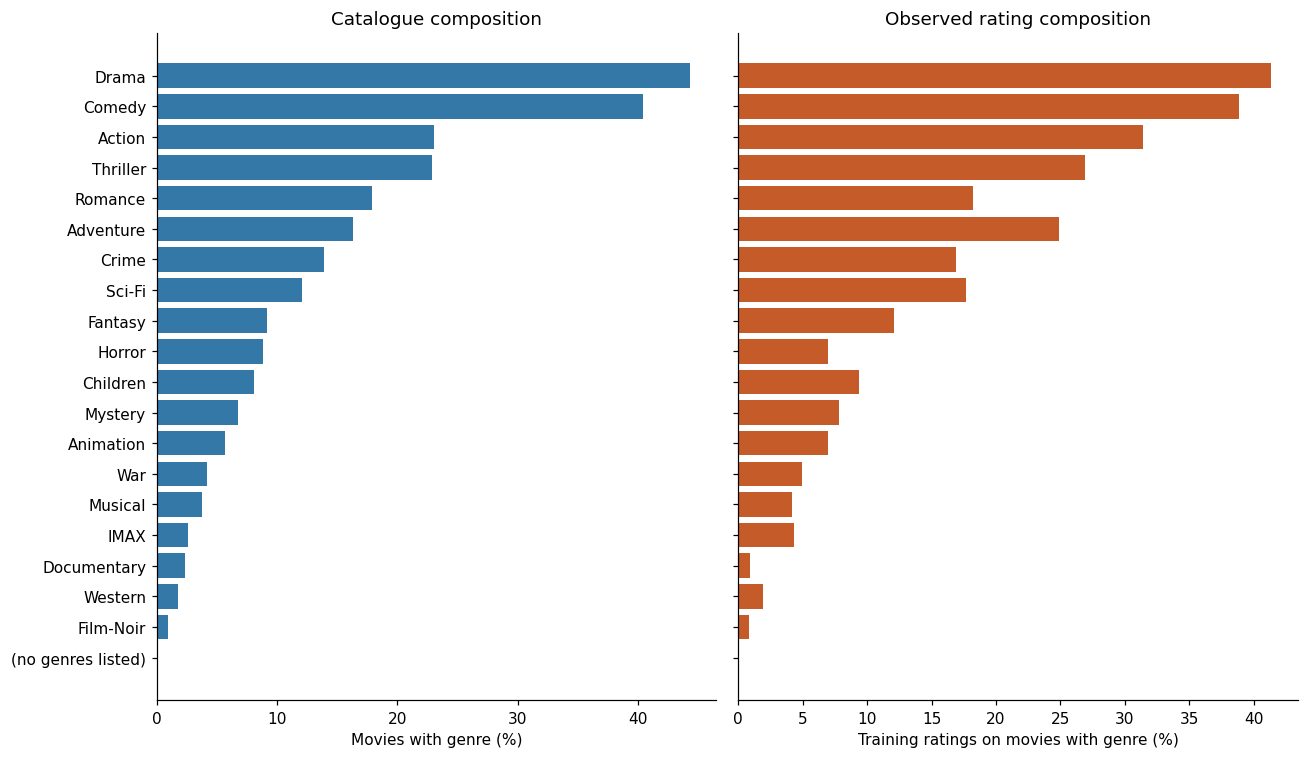

,genre,movies,observed ratings,catalogue (%),ratings (%)
0,Drama,2206,13069,44.297189,41.360213
1,Comedy,2012,12264,40.401606,38.812583
2,Action,1149,9920,23.072289,31.394392
3,Thriller,1138,8496,22.851406,26.887778
4,Romance,891,5761,17.891566,18.232167
5,Adventure,814,7855,16.345382,24.859168
6,Crime,693,5344,13.915663,16.912463
7,Sci-Fi,601,5592,12.068273,17.697323
8,Fantasy,455,3810,9.136546,12.057725
9,Horror,441,2204,8.855422,6.975125


In [9]:
genre_lists = movies['genres'].str.split('|')
genre_names = sorted({g for gs in genre_lists for g in gs})
genre_matrix = np.array([[g in gs for g in genre_names] for gs in genre_lists], dtype=float)
genre_summary = pd.DataFrame({'genre': genre_names,
    'movies': genre_matrix.sum(axis=0).astype(int),
    'observed ratings': (movie_counts @ genre_matrix).astype(int)})
genre_summary['catalogue (%)'] = 100 * genre_summary['movies'] / len(movies)
genre_summary['ratings (%)'] = 100 * genre_summary['observed ratings'] / len(values)
genre_summary = genre_summary.sort_values('movies')
fig, axes = plt.subplots(1, 2, figsize=(12, 7), sharey=True)
axes[0].barh(genre_summary['genre'], genre_summary['catalogue (%)'], color='#3478a8')
axes[1].barh(genre_summary['genre'], genre_summary['ratings (%)'], color='#c45b28')
axes[0].set(xlabel='Movies with genre (%)', title='Catalogue composition')
axes[1].set(xlabel='Training ratings on movies with genre (%)', title='Observed rating composition')
plt.tight_layout()
plt.show()
display(genre_summary.sort_values('movies', ascending=False).reset_index(drop=True))

## 7. Release years and metadata quality

The model extracts a year from a title's final `(YYYY)` and groups it into **pre-1960, 1960s, ?, 2000s, and 2010 onward**. These boundary groups are broader than decades. Missing years receive the catalogue median in the current model.

Below we keep missing years explicit rather than silently imputing them. These are movie release years, not dates when users submitted ratings; this plot cannot reveal changing user tastes over time.

Titles with no parsed year: 1
Movies with no genres listed: 2
Rows sharing a title: 0


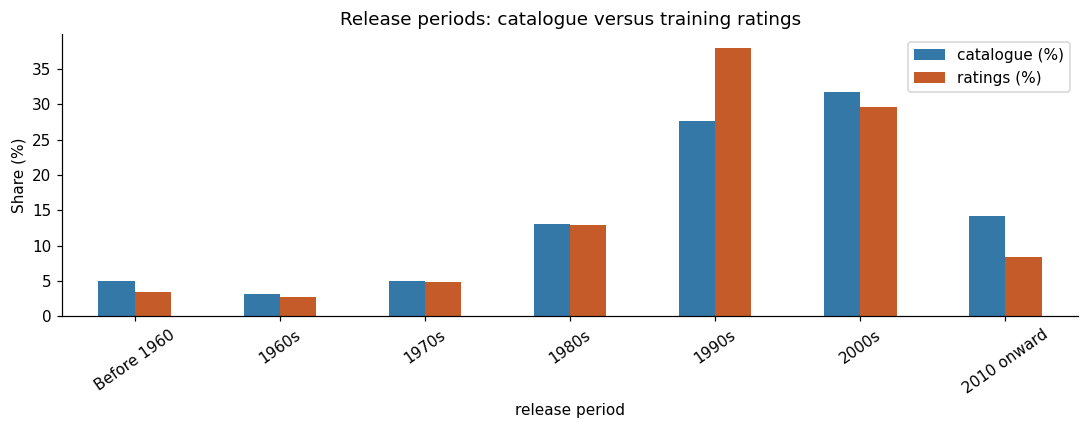

,column,movieId,title


In [8]:
edges = [-np.inf, 1960, 1970, 1980, 1990, 2000, 2010, np.inf]
periods = ['Before 1960', '1960s', '1970s', '1980s', '1990s', '2000s', '2010 onward']
movies['release period'] = pd.cut(movies['year'], edges, labels=periods, right=False)
period_summary = movies.groupby('release period', observed=False).agg(movies=('movieId', 'size'), ratings=('train_ratings', 'sum'))
period_summary['catalogue (%)'] = 100 * period_summary['movies'] / len(movies)
period_summary['ratings (%)'] = 100 * period_summary['ratings'] / len(values)
period_summary[['catalogue (%)', 'ratings (%)']].plot.bar(color=['#3478a8', '#c45b28'], rot=35)
plt.title('Release periods: catalogue versus training ratings')
plt.ylabel('Share (%)')
plt.tight_layout()
plt.show()
print('Titles with no parsed year:', int(movies['year'].isna().sum()))
print('Movies with no genres listed:', int(movies['genres'].eq('(no genres listed)').sum()))
print('Rows sharing a title:', int(movies['title'].duplicated(keep=False).sum()))
display(movies[movies['title'].duplicated(keep=False)][['column', 'movieId', 'title']].sort_values('title'))

## 8. Does the current model load these same features?

BPMF uses movie genres and release periods to guide latent movie vectors. It also summarizes **which genres and periods a user rated**, plus user activity and movie rating counts. Genre shares overlap because movies have multiple labels. Rating values influence factor learning separately.

The following cell checks the actual loader without training anything. If it reports missing or different metadata, the notebook's corrected metadata is not yet connected to the model. Do not interpret earlier metadata-model scores as measurements of the corrected version.

In [9]:
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
import models
loaded_features = models.movie_metadata(train.shape[1])
model_path = Path(models.__file__).with_name('namesngenre.npy')
print('Model metadata path:', model_path)
if loaded_features is None:
    print('ACTION NEEDED: model metadata is unavailable. Its current loader needs the corrected file beside models.py.')
    print('With side_info=True, rating-count features still work, but genre/year features are absent.')
else:
    model_meta = np.load(model_path, allow_pickle=False)
    print('Model metadata exactly matches notebook:', np.array_equal(model_meta, metadata))
    print('Model movie metadata feature shape:', loaded_features.shape)
# Reproduce feature construction from the corrected file explicitly.
years_for_model = movies['year'].fillna(movies['year'].median()).to_numpy()
period_matrix = np.column_stack([(years_for_model >= lo) & (years_for_model < hi)
                                for lo, hi in zip(edges[:-1], edges[1:])]).astype(float)
corrected_features = np.column_stack([genre_matrix, period_matrix])
user_features, movie_features = models.side_features(train, corrected_features)
print('Corrected feature shapes: users', user_features.shape, '; movies', movie_features.shape)
print('Columns: intercept, log(1 + training count), 20 genre indicators/shares, 7 release-period indicators/shares.')
user_genre_shares = observed[example_user].astype(float) @ genre_matrix / max(user_counts[example_user], 1)
display(pd.Series(user_genre_shares, index=genre_names, name='Share of this user?s rated movies').sort_values(ascending=False).head(10).to_frame())

Model metadata path: C:\Users\User\Desktop\Mines_Paris_cours\IASD_master\DataLab\repos\masteriasd-datalab-project-a1-group-38\namesngenre.npy
ACTION NEEDED: model metadata is unavailable. Its current loader needs the corrected file beside models.py.
With side_info=True, rating-count features still work, but genre/year features are absent.
Corrected feature shapes: users (610, 29) ; movies (4980, 29)
Columns: intercept, log(1 + training count), 20 genre indicators/shares, 7 release-period indicators/shares.


,Share of this user?s rated movies
Action,0.478873
Adventure,0.436620
Thriller,0.323944
Comedy,0.309859
Drama,0.267606
Sci-Fi,0.225352
Fantasy,0.211268
Children,0.183099
Crime,0.183099
Animation,0.154930


## 9. What this tells us?and what comes next

Use the outputs above to answer these questions in your own words:

1. How much evidence does a typical user or movie have? How different is the long tail?
2. Which rating values are common? Why might a small overall RMSE still hide poor extreme-rating predictions?
3. Which genres and release periods dominate the catalogue, and which dominate observed ratings?
4. Is the corrected metadata actually being used by the model?

**Next experiment:** connect the corrected metadata to the model, freeze an evaluation protocol, and compare bias, plain BPMF, and BPMF with corrected side information on identical held-out cells. Then inspect signed residuals (`prediction ? truth`), absolute errors, and squared errors by user support, movie support, true rating, genre, and release period. Report group sizes alongside errors.

Descriptive patterns suggest hypotheses; they do not prove the model succeeds or fails. Earlier aggregate CSVs contain no per-rating predictions, so a fresh evaluation with saved predictions will be needed for error analysis. Historical ablations also need their obsolete `merged_split` import repaired before reuse. Keep evaluation labels out of feature construction and model selection, and disclose the project's earlier use of supplied test labels.

**Scope of this notebook:** training-data exploration only. No new model-performance claim, metadata replacement, or model training is performed.